# Proyecto 3 – Aprendizaje no supervisado y reducción de dimensión

**Curso:** Machine Learning · Universidad de Medellín  
**Base de datos:** *Sleep Health and Lifestyle Dataset* (Kaggle, `uom190346a`)  
**Problema:** analizar si los datos de estilo de vida permiten distinguir tres categorías de `Sleep Disorder`: `Insomnia`, `Sleep Apnea` y `None`.

| Parte | Contenido |
|---|---|
| 1 | Descripción del dataset, análisis exploratorio y clustering con K-means, clustering jerárquico aglomerativo y DBSCAN. |
| 2 | Selección de características SFFS con wrappers, clasificación con una red neuronal MLP, PCA y LDA. |

> **Importante:** las etiquetas `Sleep Disorder` no se utilizan para construir los clusters de la Parte 1; únicamente se usan después para evaluar qué tan similares son los agrupamientos a las clases originales. En la Parte 2 sí se usan como variable objetivo supervisada.

# PARTE 1

## 1. Descripción de la base de datos

**Fuente:** <https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset>

**Dominio del problema:** salud y bienestar. El dataset recoge hábitos de sueño y estilo de vida de 374 personas (edad, ocupación, actividad física, estrés, indicadores cardiovasculares, etc.) junto con el diagnóstico de un trastorno del sueño.

**Utilidad:** identificar qué factores del estilo de vida y de la salud se asocian con el insomnio o la apnea del sueño permite construir sistemas de tamizaje (*screening*) temprano y orientar intervenciones preventivas. Es un problema donde las clases tienen un significado clínico claro, lo que facilita interpretar los resultados de clustering y de selección de características.

**Tipo de problema:** clasificación **multiclase** (3 clases). En la Parte 1 se usa aprendizaje **no supervisado** (la etiqueta solo se emplea para *evaluar* qué tanto los clusters recuperan las clases); en la Parte 2 se usa aprendizaje **supervisado** con reducción de dimensión.

**Variable de salida:** `Sleep Disorder` ∈ {`None`, `Insomnia`, `Sleep Apnea`}.

| Variable | Tipo | Descripción |
|---|---|---|
| `Person ID` | identificador | Identificador de la persona (se descarta, no aporta información) |
| `Gender` | categórica nominal (2) | Male / Female |
| `Age` | numérica discreta | Edad en años |
| `Occupation` | categórica nominal (11) | Profesión de la persona |
| `Sleep Duration` | numérica continua | Horas de sueño por día |
| `Quality of Sleep` | ordinal (1–10) | Calidad del sueño auto-reportada |
| `Physical Activity Level` | numérica | Minutos de actividad física por día |
| `Stress Level` | ordinal (1–10) | Nivel de estrés auto-reportado |
| `BMI Category` | categórica ordinal | Normal / Overweight / Obese |
| `Blood Pressure` | texto `sistólica/diastólica` | Presión arterial (se separa en dos variables numéricas) |
| `Heart Rate` | numérica | Frecuencia cardíaca en reposo (lpm) |
| `Daily Steps` | numérica | Pasos por día |
| `Sleep Disorder` | **salida** categórica (3) | None / Insomnia / Sleep Apnea |

> **Detalle importante:** en el CSV la clase "sin trastorno" está escrita literalmente como el texto `None`. Pandas lo interpreta por defecto como valor faltante (`NaN`). Por eso se carga con `keep_default_na=False`.

In [ ]:
# Instala las dependencias que no suelen venir incluidas en un entorno básico.
# Ejecuta esta celda una vez al iniciar el entorno.
%pip install -q mlxtend kagglehub

In [ ]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_completeness_v_measure, accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.metrics.cluster import contingency_matrix
from sklearn.model_selection import (
    cross_validate, StratifiedGroupKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
from scipy.cluster.hierarchy import linkage, dendrogram
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

warnings.filterwarnings("once", category=ConvergenceWarning)
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

In [ ]:
# ---- Carga de datos -------------------------------------------------------
# Opción A: coloca el CSV junto a este notebook.
# Opción B: si no está localmente, intenta descargar el dataset público con kagglehub.
CSV = "Sleep_health_and_lifestyle_dataset.csv"

if not os.path.exists(CSV):
    try:
        import kagglehub
        dataset_path = kagglehub.dataset_download("uom190346a/sleep-health-and-lifestyle-dataset")
        csv_files = glob.glob(os.path.join(dataset_path, "**", "*.csv"), recursive=True)
        if not csv_files:
            raise FileNotFoundError("kagglehub descargó el dataset, pero no se encontró ningún archivo CSV.")
        CSV = csv_files[0]
    except Exception as exc:
        raise FileNotFoundError(
            "No se encontró el CSV localmente ni fue posible descargarlo. Descarga el archivo "
            "Sleep_health_and_lifestyle_dataset.csv desde Kaggle y colócalo junto al notebook."
        ) from exc

df = pd.read_csv(CSV, keep_default_na=False, na_values=[""])
df.columns = df.columns.str.strip()

required_columns = {
    "Person ID", "Gender", "Age", "Occupation", "Sleep Duration",
    "Quality of Sleep", "Physical Activity Level", "Stress Level",
    "BMI Category", "Blood Pressure", "Heart Rate", "Daily Steps", "Sleep Disorder"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Al CSV le faltan columnas requeridas: {sorted(missing_columns)}")

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Archivo:", CSV)
print("Dimensiones:", df.shape)
print("Clases observadas:", sorted(df["Sleep Disorder"].dropna().unique().tolist()))
df.head()

Using Colab cache for faster access to the 'sleep-health-and-lifestyle-dataset' dataset.
Archivo: /kaggle/input/sleep-health-and-lifestyle-dataset/Sleep_health_and_lifestyle_dataset.csv
Dimensiones: (374, 13)
Clases observadas: ['Insomnia', 'None', 'Sleep Apnea']


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 2. Análisis exploratorio de datos (EDA)

In [ ]:
print("Información general:")
df.info()
print("\nValores faltantes por columna:")
display(df.isna().sum().to_frame("Valores faltantes"))

sin_id = df.drop(columns=["Person ID"])
print("Filas duplicadas al ignorar Person ID:", int(sin_id.duplicated().sum()))

# Perfiles de entrada idénticos que aparecen asociados a más de una etiqueta.
columnas_entrada_originales = [c for c in df.columns if c not in ["Person ID", "Sleep Disorder"]]
perfiles = df.groupby(columnas_entrada_originales, dropna=False)["Sleep Disorder"].nunique()
print("Perfiles de entrada idénticos asociados a más de una clase:", int((perfiles > 1).sum()))

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB



,Valores faltantes
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


Filas duplicadas al ignorar Person ID: 242
Perfiles de entrada idénticos asociados a más de una clase: 22


In [ ]:
# Resumen estadístico mixto: incluye columnas numéricas y categóricas.
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Person ID,374.0,NaN,NaN,NaN,187.5,108.108742,1.0,94.25,187.5,280.75,374.0
Gender,374,2,Male,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,374.0,NaN,NaN,NaN,42.184492,8.673133,27.0,35.25,43.0,50.0,59.0
Occupation,374,11,Nurse,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Duration,374.0,NaN,NaN,NaN,7.132086,0.795657,5.8,6.4,7.2,7.8,8.5
Quality of Sleep,374.0,NaN,NaN,NaN,7.312834,1.196956,4.0,6.0,7.0,8.0,9.0
Physical Activity Level,374.0,NaN,NaN,NaN,59.171123,20.830804,30.0,45.0,60.0,75.0,90.0
Stress Level,374.0,NaN,NaN,NaN,5.385027,1.774526,3.0,4.0,5.0,7.0,8.0
BMI Category,374,4,Normal,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Pressure,374,25,130/85,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Rango observado y variabilidad de las variables numéricas originales.
num_cols = [
    "Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
    "Stress Level", "Heart Rate", "Daily Steps"
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

rangos = pd.DataFrame({
    "Tipo": ["Discreta" if c in ["Age", "Quality of Sleep", "Stress Level", "Heart Rate", "Daily Steps"] else "Numérica (puede ser continua)" for c in num_cols],
    "Mínimo": df[num_cols].min(),
    "Máximo": df[num_cols].max(),
    "Media": df[num_cols].mean().round(2),
    "Desv. estándar": df[num_cols].std().round(2),
    "Valores únicos": df[num_cols].nunique()
})
display(rangos)

,Tipo,Mínimo,Máximo,Media,Desv. estándar,Valores únicos
Age,Discreta,27.0,59.0,42.18,8.67,31
Sleep Duration,Numérica (puede ser continua),5.8,8.5,7.13,0.80,27
Quality of Sleep,Discreta,4.0,9.0,7.31,1.20,6
Physical Activity Level,Numérica (puede ser continua),30.0,90.0,59.17,20.83,16
Stress Level,Discreta,3.0,8.0,5.39,1.77,6
Heart Rate,Discreta,65.0,86.0,70.17,4.14,19
Daily Steps,Discreta,3000.0,10000.0,6816.84,1617.92,20


In [ ]:
# Distribución de todas las variables categóricas originales.
cat_cols = ["Gender", "Occupation", "BMI Category", "Blood Pressure", "Sleep Disorder"]
for c in cat_cols:
    print(f"--- {c} ---")
    display(df[c].value_counts(dropna=False).rename_axis(c).to_frame("Frecuencia"))

--- Gender ---


,Frecuencia
Gender,
Male,189
Female,185


--- Occupation ---


,Frecuencia
Occupation,
Nurse,73
Doctor,71
Engineer,63
Lawyer,47
Teacher,40
Accountant,37
Salesperson,32
Scientist,4
Software Engineer,4


--- BMI Category ---


,Frecuencia
BMI Category,
Normal,195
Overweight,148
Normal Weight,21
Obese,10


--- Blood Pressure ---


,Frecuencia
Blood Pressure,
130/85,99
140/95,65
125/80,65
120/80,45
115/75,32
135/90,27
140/90,4
125/82,4
128/85,3


--- Sleep Disorder ---


,Frecuencia
Sleep Disorder,
None,219
Sleep Apnea,78
Insomnia,77


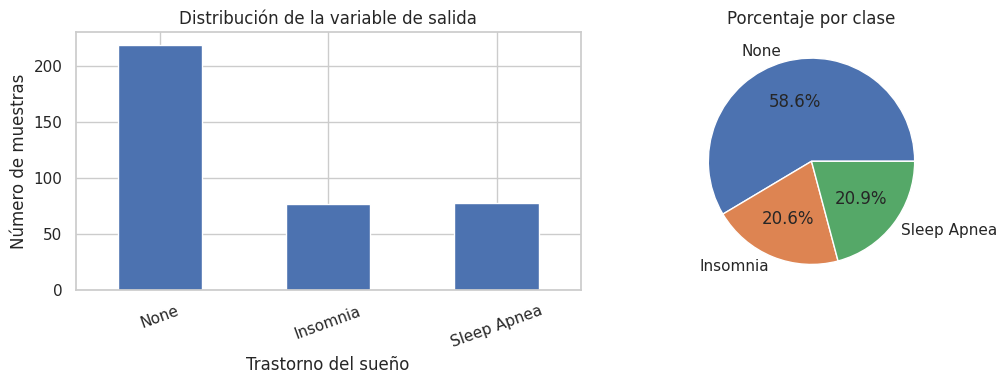

Porcentaje de cada clase:


,Porcentaje (%)
Sleep Disorder,
None,58.56
Insomnia,20.59
Sleep Apnea,20.86


In [ ]:
# Distribución de la variable de salida: conteos y porcentajes.
orden = [c for c in ["None", "Insomnia", "Sleep Apnea"] if c in set(df["Sleep Disorder"])]
conteos = df["Sleep Disorder"].value_counts().reindex(orden, fill_value=0)
porcentajes = df["Sleep Disorder"].value_counts(normalize=True).reindex(orden, fill_value=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
conteos.plot(kind="bar", ax=ax[0])
ax[0].set_title("Distribución de la variable de salida")
ax[0].set_xlabel("Trastorno del sueño")
ax[0].set_ylabel("Número de muestras")
ax[0].tick_params(axis="x", rotation=20)
porcentajes.plot.pie(autopct="%.1f%%", ax=ax[1], ylabel="")
ax[1].set_title("Porcentaje por clase")
plt.tight_layout()
plt.show()
print("Porcentaje de cada clase:")
display(porcentajes.round(2).rename("Porcentaje (%)").to_frame())

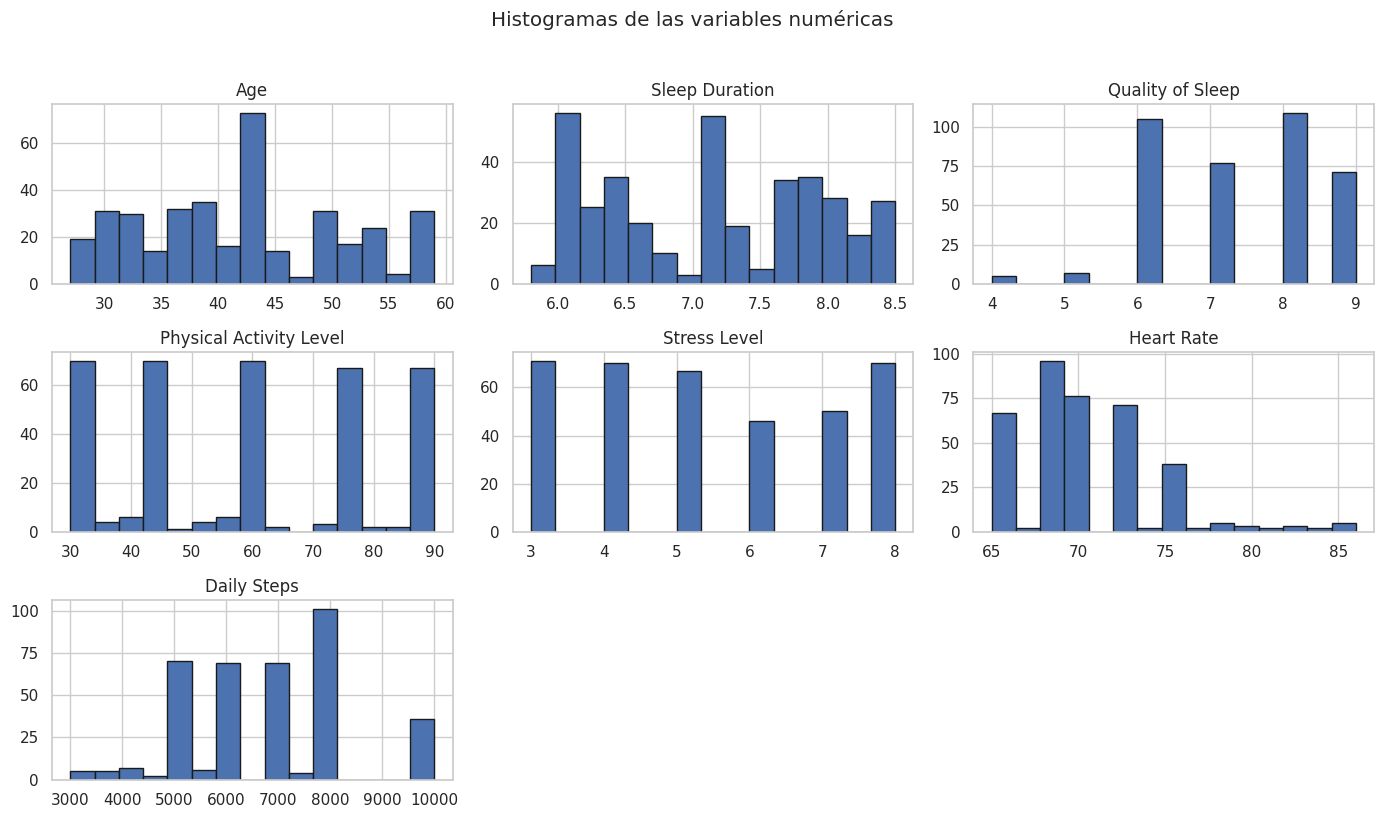

In [ ]:
# Histogramas de variables numéricas
df[num_cols].hist(bins=15, figsize=(14, 8), edgecolor="k")
plt.suptitle("Histogramas de las variables numéricas", y=1.02)
plt.tight_layout(); plt.show()

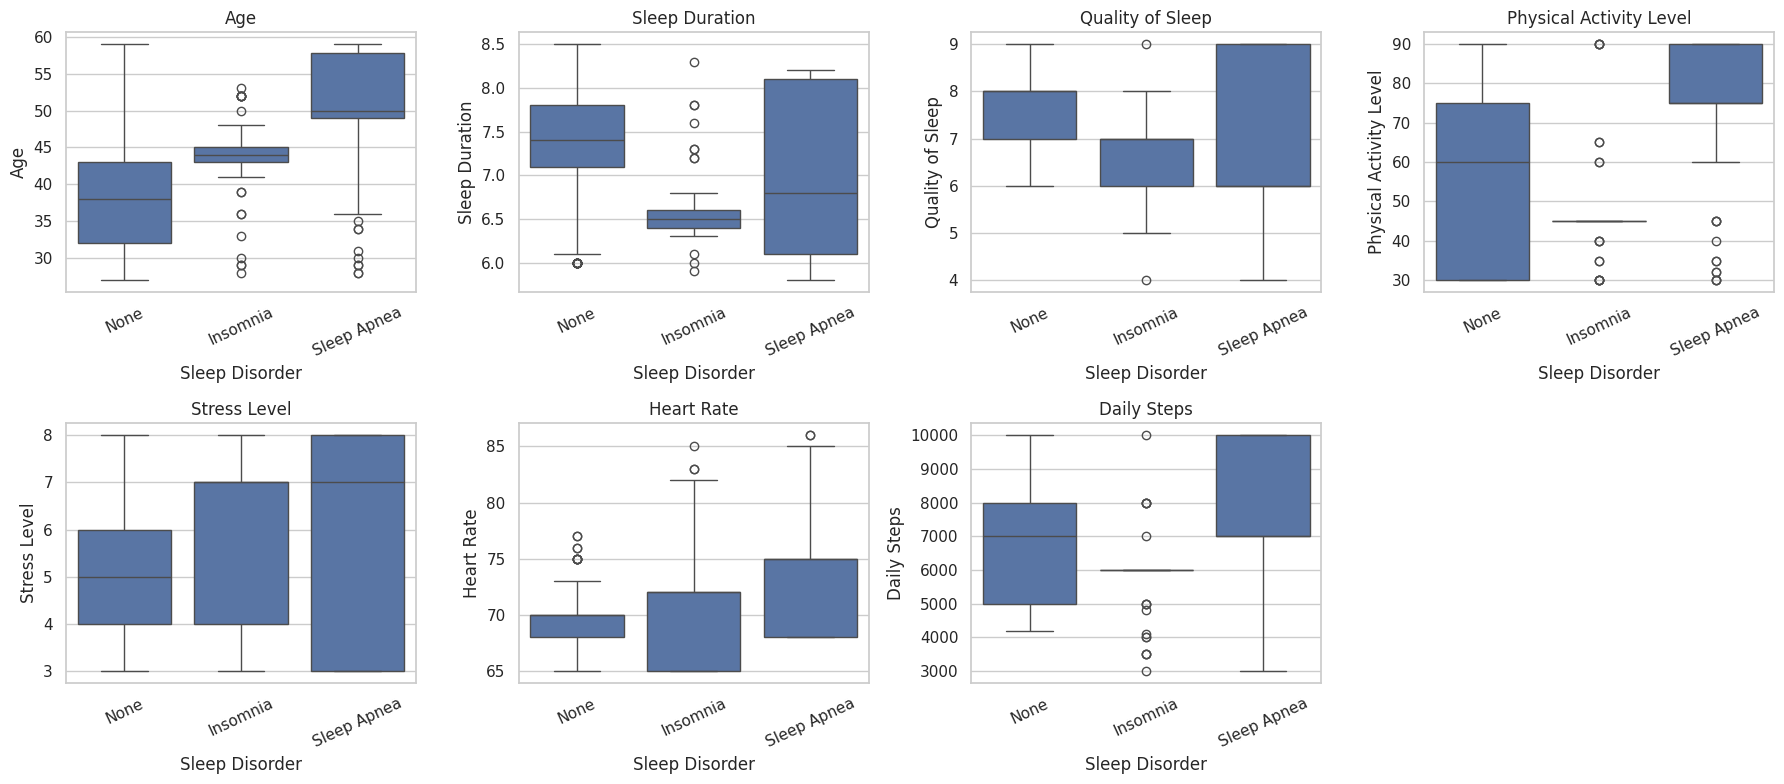

In [ ]:
# Variables numéricas frente a la clase de salida.
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="Sleep Disorder", y=c, order=orden, ax=ax)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=25)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

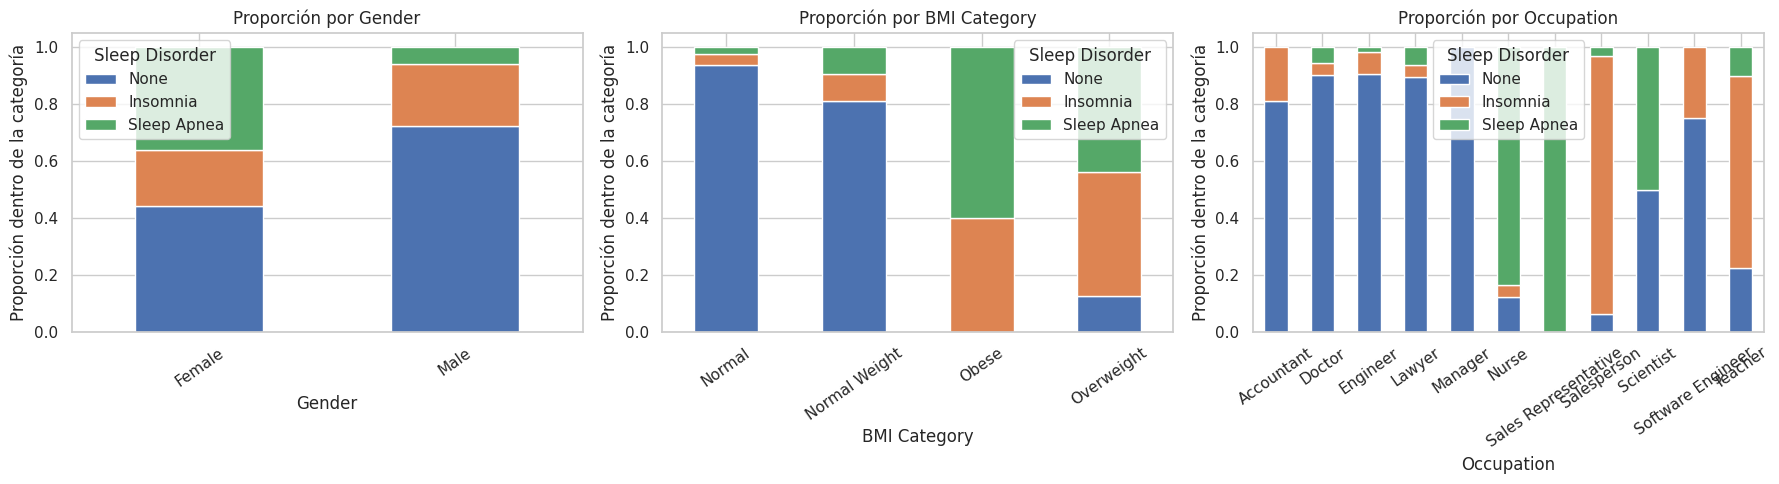

In [ ]:
# Variables categóricas frente a la clase. Se muestran proporciones en lugar de
# interpretar solamente conteos, porque las clases de salida están desbalanceadas.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ["Gender", "BMI Category", "Occupation"]):
    tab = pd.crosstab(df[c], df["Sleep Disorder"], normalize="index").reindex(columns=orden, fill_value=0)
    tab.plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"Proporción por {c}")
    ax.set_ylabel("Proporción dentro de la categoría")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

### 2.1 Preprocesamiento

- `Person ID` se elimina porque es un identificador, no una característica explicativa.
- `Blood Pressure` se separa en dos columnas numéricas: presión sistólica y diastólica.
- Se unifican las etiquetas equivalentes `Normal Weight` y `Normal` de `BMI Category`; esta categoría se codifica ordinalmente (`Normal` = 0, `Overweight` = 1, `Obese` = 2).
- `Gender` se codifica como binaria y `Occupation` mediante *one-hot encoding*.
- Para clustering se estandarizan las características, porque las variables tienen escalas distintas. En la Parte 2 el escalador se ajusta dentro de cada partición de validación para evitar fuga de información.
- La variable de salida se codifica con `LabelEncoder`, pero se excluye de la matriz de características `X`.

In [ ]:
# Copia de trabajo y transformación de Blood Pressure.
d = df.copy().drop(columns=["Person ID"])
bp = d["Blood Pressure"].astype(str).str.replace(" ", "", regex=False).str.split("/", expand=True)
if bp.shape[1] != 2:
    raise ValueError("La columna Blood Pressure debe tener formato sistólica/diastólica, por ejemplo '126/83'.")
d["Systolic"] = pd.to_numeric(bp[0], errors="coerce")
d["Diastolic"] = pd.to_numeric(bp[1], errors="coerce")
d = d.drop(columns=["Blood Pressure"])

d["BMI Category"] = d["BMI Category"].replace({"Normal Weight": "Normal"})
d["BMI_ord"] = d["BMI Category"].map({"Normal": 0, "Overweight": 1, "Obese": 2})
d["Gender_Male"] = d["Gender"].map({"Male": 1, "Female": 0})
if d[["BMI_ord", "Gender_Male", "Systolic", "Diastolic"]].isna().any().any():
    raise ValueError("Hay valores no reconocidos en BMI Category, Gender o Blood Pressure; revisa las categorías del CSV.")

num_feats = [
    "Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
    "Stress Level", "Heart Rate", "Daily Steps", "Systolic", "Diastolic"
]
occ = pd.get_dummies(d["Occupation"], prefix="Occ", dtype=int)
X = pd.concat([d[num_feats].reset_index(drop=True),
               d[["BMI_ord", "Gender_Male"]].reset_index(drop=True),
               occ.reset_index(drop=True)], axis=1).astype(float)

le = LabelEncoder()
y = le.fit_transform(d["Sleep Disorder"].astype(str))
clases = list(le.classes_)
n_clases = len(clases)
if n_clases < 2:
    raise ValueError("La variable Sleep Disorder debe contener al menos dos clases.")
print("Clases codificadas:", dict(zip(range(n_clases), clases)))
print("Número de muestras:", len(X))
print("Número de características tras codificar:", X.shape[1])
print("Características:", list(X.columns))

# Estandarización global solo para la exploración de clustering no supervisado.
# En la Parte 1 no se utiliza y para ajustar el escalador.
X_s = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

Clases codificadas: {0: 'Insomnia', 1: 'None', 2: 'Sleep Apnea'}
Número de muestras: 374
Número de características tras codificar: 22
Características: ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic', 'Diastolic', 'BMI_ord', 'Gender_Male', 'Occ_Accountant', 'Occ_Doctor', 'Occ_Engineer', 'Occ_Lawyer', 'Occ_Manager', 'Occ_Nurse', 'Occ_Sales Representative', 'Occ_Salesperson', 'Occ_Scientist', 'Occ_Software Engineer', 'Occ_Teacher']


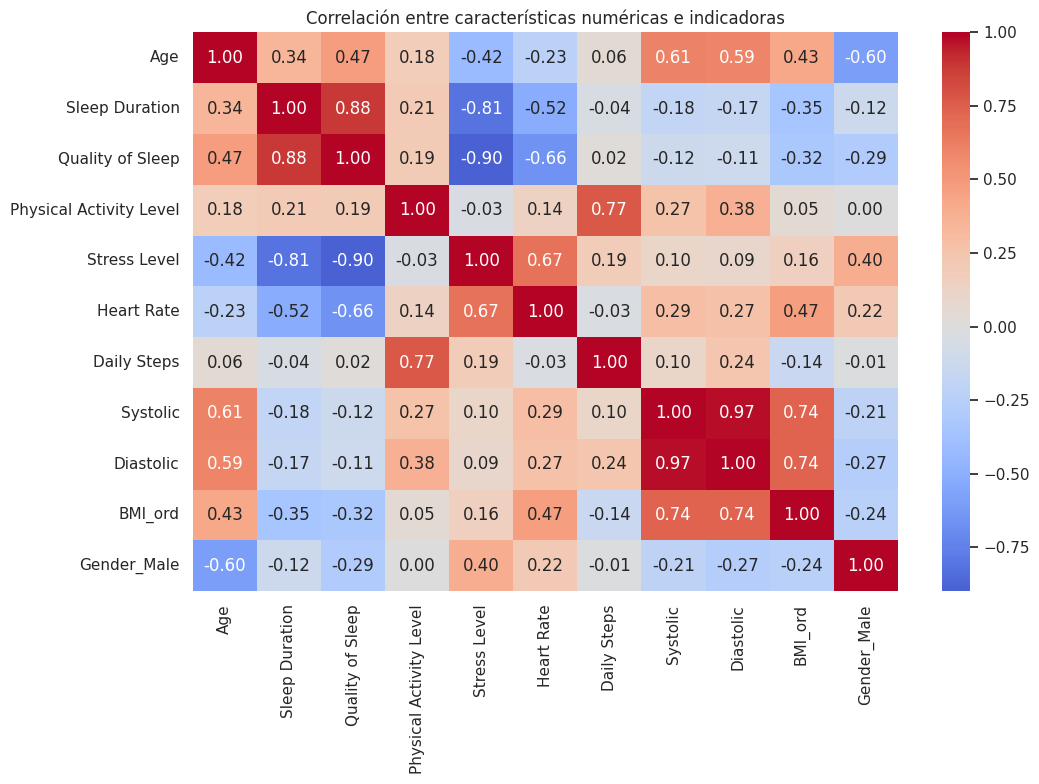

In [ ]:
# Correlaciones entre características numéricas/indicadoras.
# No se correlaciona con y codificada como 0/1/2, pues esos códigos no tienen
# una interpretación numérica ordinal para las clases.
cols_corr = num_feats + ["BMI_ord", "Gender_Male"]
corr = X[cols_corr].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre características numéricas e indicadoras")
plt.tight_layout()
plt.show()

### 2.2 Análisis preliminar

Al ejecutar las celdas anteriores, comenta los resultados observados, no solamente lo que se esperaba observar:

- **Tamaño y balance:** reporta el número real de muestras y el porcentaje de cada clase que imprime la celda de distribución. Si hay desbalance, la exactitud debe acompañarse de F1 macro.
- **Escalas:** `Daily Steps` suele tener valores de miles, mientras `Sleep Duration` está en horas y escalas ordinales como `Stress Level` toman pocos valores. Esto justifica estandarizar antes de los algoritmos basados en distancia.
- **Tipos de variable:** `Quality of Sleep` y `Stress Level` son ordinales; `Gender`, `Occupation` y `BMI Category` son categóricas; presión arterial se transforma en dos variables numéricas.
- **Relaciones entre clases:** compara los boxplots y las proporciones por categoría para identificar qué variables podrían discriminar entre clases. No afirmes relaciones clínicas causales: este dataset observacional no demuestra causalidad.
- **Perfiles repetidos:** los perfiles de entrada idénticos pueden afectar DBSCAN y facilitar la clasificación si se reparten entre entrenamiento y prueba. Por eso, en la Parte 2 los perfiles idénticos se mantienen en la misma partición mediante validación por grupos.
- **Datos faltantes:** comprueba la tabla de valores faltantes. La etiqueta literal `None` debe mantenerse como clase válida.

## 3. Aprendizaje no supervisado (clustering)

Se aplican **K-means**, **clustering jerárquico aglomerativo** y **DBSCAN** **sin usar** `Sleep Disorder`. La etiqueta solo se utiliza después para medir qué tan bien los grupos recrean las clases:

- **ARI** (Adjusted Rand Index): 1 = agrupamiento idéntico a las clases, ≈ 0 = aleatorio.
- **NMI**: información mutua normalizada.
- **Homogeneidad / Completitud / V-measure**.
- **Pureza**: fracción de muestras que pertenecen a la clase mayoritaria de su cluster.
- **Silhouette**: métrica interna (no usa etiquetas).

Se prueban distintos números de clusters (k = 2…8), **incluyendo k = 3**, que es el número de clases del problema.

In [ ]:
def pureza(y_true, labels):
    """Proporción de observaciones asignadas a la clase mayoritaria de su cluster."""
    cm = contingency_matrix(y_true, labels)
    return cm.max(axis=0).sum() / cm.sum()


def evaluar(X_eval, y_true, labels):
    """Métricas externas contra clases reales y Silhouette interna.

    En DBSCAN, -1 (ruido) se conserva como una etiqueta al calcular ARI/NMI,
    y se excluye del cálculo de Silhouette para evaluar los clusters detectados.
    """
    h, c, v = homogeneity_completeness_v_measure(y_true, labels)
    mask = np.asarray(labels) != -1
    labels_sin_ruido = np.asarray(labels)[mask]
    n_clusters_sin_ruido = len(np.unique(labels_sin_ruido))
    n_muestras_sin_ruido = int(mask.sum())
    sil = np.nan
    if 2 <= n_clusters_sin_ruido < n_muestras_sin_ruido:
        try:
            sil = silhouette_score(np.asarray(X_eval)[mask], labels_sin_ruido)
        except ValueError:
            sil = np.nan
    return {
        "ARI": adjusted_rand_score(y_true, labels),
        "NMI": normalized_mutual_info_score(y_true, labels),
        "Homog.": h,
        "Compl.": c,
        "V-measure": v,
        "Pureza": pureza(y_true, labels),
        "Silhouette": sil
    }

resultados = []
Xc = X_s.to_numpy()

### 3.1 K-means

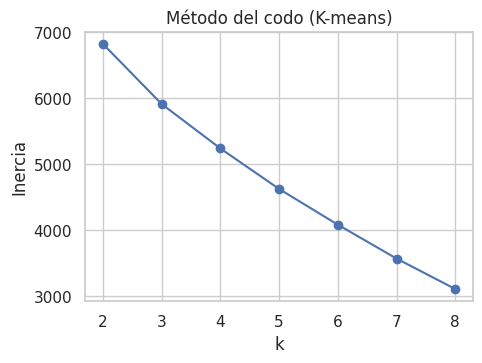

,Config,k,ARI,NMI,Homog.,Compl.,V-measure,Pureza,Silhouette
0,k=2,2,0.591,0.498,0.425,0.601,0.498,0.735,0.240
1,k=3,3,0.269,0.302,0.311,0.294,0.302,0.730,0.277
2,k=4,4,0.388,0.395,0.469,0.341,0.395,0.816,0.308
3,k=5,5,0.282,0.349,0.456,0.282,0.349,0.781,0.371
4,k=6,6,0.305,0.410,0.577,0.318,0.410,0.874,0.427
5,k=7,7,0.225,0.362,0.542,0.272,0.362,0.853,0.493
6,k=8,8,0.202,0.354,0.553,0.261,0.354,0.858,0.558


In [ ]:
inercias = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xc)
    inercias.append(km.inertia_)
    resultados.append({"Modelo": "K-means", "Config": f"k={k}", "k": k,
                       "Ruido": 0, **evaluar(Xc, y, km.labels_)})

plt.figure(figsize=(5, 3.5))
plt.plot(range(2, 9), inercias, "o-"); plt.xlabel("k"); plt.ylabel("Inercia")
plt.title("Método del codo (K-means)"); plt.show()

pd.DataFrame([r for r in resultados if r["Modelo"] == "K-means"]).drop(columns=["Modelo", "Ruido"]).round(3)

### 3.2 Clustering jerárquico aglomerativo

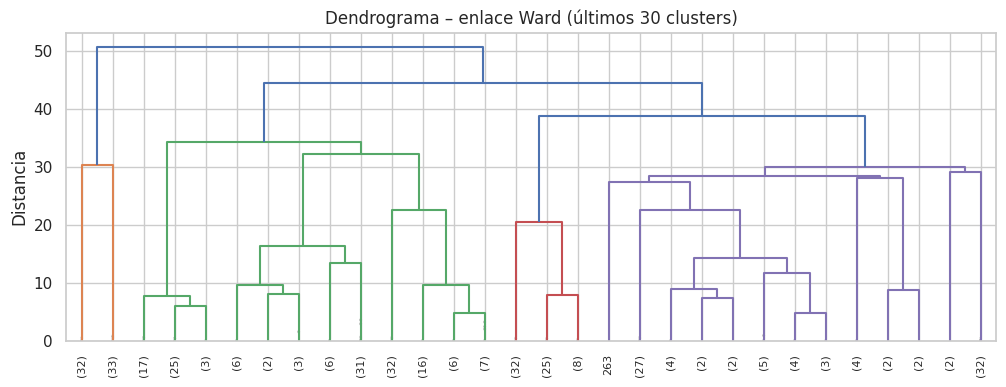

Modelo,Jerárquico (average),Jerárquico (complete),Jerárquico (single),Jerárquico (ward)
k,,,,
2,-0.003,-0.003,-0.003,0.341
3,0.005,0.005,0.005,0.314
4,0.001,0.001,0.001,0.420
5,0.003,0.003,0.003,0.305
6,0.032,0.147,0.147,0.242
7,0.383,0.343,0.279,0.216
8,0.383,0.343,0.270,0.204


In [ ]:
# Dendrograma (Ward)
Z = linkage(Xc, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, show_contracted=True)
plt.title("Dendrograma – enlace Ward (últimos 30 clusters)"); plt.ylabel("Distancia"); plt.show()

for link in ["ward", "complete", "average", "single"]:
    for k in range(2, 9):
        ag = AgglomerativeClustering(n_clusters=k, linkage=link).fit(Xc)
        resultados.append({"Modelo": f"Jerárquico ({link})", "Config": f"k={k}", "k": k,
                           "Ruido": 0, **evaluar(Xc, y, ag.labels_)})

pd.DataFrame([r for r in resultados if r["Modelo"].startswith("Jerárquico")]) \
  .pivot_table(index="k", columns="Modelo", values="ARI").round(3)

### 3.3 DBSCAN

DBSCAN no recibe el número de clusters como parámetro: el resultado depende de `eps` (radio) y `min_samples`. Se explora una rejilla de combinaciones y se registra el número de clusters detectados y la cantidad de muestras clasificadas como ruido (`-1`).

Para comparar DBSCAN con los otros algoritmos, ARI/NMI/pureza consideran `-1` como una etiqueta más. La métrica Silhouette, en cambio, se calcula solo con las muestras asignadas a clusters y queda como `NaN` si no hay suficientes clusters para calcularla.

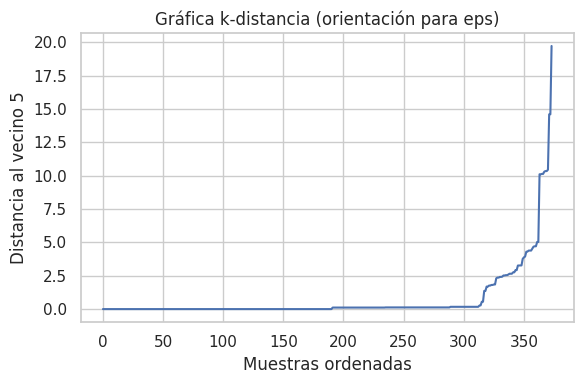

Combinaciones de DBSCAN con al menos un cluster: 60


,Modelo,Config,k,Ruido,ARI,NMI,Homog.,Compl.,V-measure,Pureza,Silhouette
31,DBSCAN,"eps=4.5, ms=12",4,22,0.480,0.402,0.422,0.384,0.402,0.805,0.352
30,DBSCAN,"eps=4.5, ms=8",3,18,0.294,0.260,0.233,0.295,0.260,0.730,0.257
28,DBSCAN,"eps=4.5, ms=3",4,9,0.270,0.258,0.228,0.297,0.258,0.730,0.254
29,DBSCAN,"eps=4.5, ms=5",3,13,0.270,0.259,0.226,0.303,0.259,0.730,0.248
21,DBSCAN,"eps=3.5, ms=5",10,22,0.201,0.348,0.577,0.249,0.348,0.864,0.699
20,DBSCAN,"eps=3.5, ms=3",12,11,0.201,0.347,0.585,0.247,0.347,0.869,0.692
22,DBSCAN,"eps=3.5, ms=8",8,35,0.198,0.350,0.566,0.253,0.350,0.861,0.711
23,DBSCAN,"eps=3.5, ms=12",8,35,0.198,0.350,0.566,0.253,0.350,0.861,0.711
24,DBSCAN,"eps=4.0, ms=3",11,11,0.196,0.338,0.561,0.241,0.338,0.856,0.681
26,DBSCAN,"eps=4.0, ms=8",8,28,0.196,0.342,0.553,0.248,0.342,0.850,0.690


In [ ]:
# Gráfica k-distancia para orientar la elección de eps.
ms_ref = 5
dist, _ = NearestNeighbors(n_neighbors=ms_ref).fit(Xc).kneighbors(Xc)
plt.figure(figsize=(6, 4))
plt.plot(np.sort(dist[:, -1]))
plt.xlabel("Muestras ordenadas")
plt.ylabel(f"Distancia al vecino {ms_ref}")
plt.title("Gráfica k-distancia (orientación para eps)")
plt.tight_layout()
plt.show()

for eps in np.arange(1.0, 8.01, 0.5):
    for ms in [3, 5, 8, 12]:
        lab = DBSCAN(eps=float(eps), min_samples=ms).fit_predict(Xc)
        k_real = len(set(lab) - {-1})
        if k_real < 1:
            # No se guarda una configuración que etiquete todas las muestras como ruido.
            continue
        resultados.append({
            "Modelo": "DBSCAN", "Config": f"eps={eps:.1f}, ms={ms}",
            "k": k_real, "Ruido": int((lab == -1).sum()),
            **evaluar(Xc, y, lab)
        })

db = pd.DataFrame([r for r in resultados if r["Modelo"] == "DBSCAN"])
print("Combinaciones de DBSCAN con al menos un cluster:", len(db))
if not db.empty:
    display(db.sort_values("ARI", ascending=False).head(10).round(3))
else:
    print("Ninguna combinación produjo clusters con la rejilla actual. Ajusta el rango de eps.")

### 3.4 Comparación de modelos y selección del mejor

Se comparan los modelos **con k = 3** (el número real de clases). Para DBSCAN se toma la mejor configuración que produzca exactamente 3 clusters (sin contar ruido); si ninguna lo logra, se reporta la mejor configuración con k más cercano a 3.

In [ ]:
R = pd.DataFrame(resultados)

# Para cada variante se prioriza k = número real de clases. Si DBSCAN no produce
# ese k, se conservan todas las configuraciones con el k más cercano y se elige
# entre ellas la de mayor ARI.
filas = []
for modelo, g in R.groupby("Modelo", sort=False):
    g = g.copy()
    exactas = g[g["k"] == n_clases]
    if not exactas.empty:
        candidatas = exactas
    else:
        distancia_minima = (g["k"] - n_clases).abs().min()
        candidatas = g[(g["k"] - n_clases).abs() == distancia_minima]
    filas.append(candidatas.sort_values(["ARI", "NMI", "Pureza"], ascending=False).iloc[0])

comp = pd.DataFrame(filas).sort_values("ARI", ascending=False).reset_index(drop=True)
display(comp.round(3))

,Modelo,Config,k,Ruido,ARI,NMI,Homog.,Compl.,V-measure,Pureza,Silhouette
0,Jerárquico (ward),k=3,3,0,0.314,0.359,0.372,0.347,0.359,0.730,0.269
1,DBSCAN,"eps=4.5, ms=8",3,18,0.294,0.260,0.233,0.295,0.260,0.730,0.257
2,K-means,k=3,3,0,0.269,0.302,0.311,0.294,0.302,0.730,0.277
3,Jerárquico (complete),k=3,3,0,0.005,0.019,0.010,0.190,0.019,0.591,0.629
4,Jerárquico (average),k=3,3,0,0.005,0.019,0.010,0.190,0.019,0.591,0.629
5,Jerárquico (single),k=3,3,0,0.005,0.019,0.010,0.190,0.019,0.591,0.629


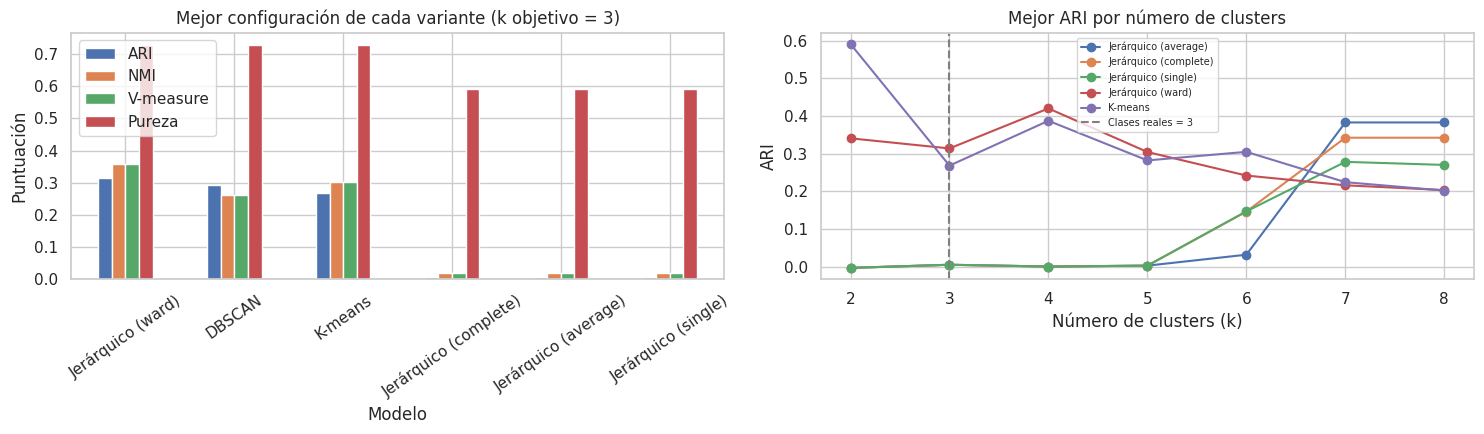

Mejor variante según ARI cerca de k=3: Jerárquico (ward) [k=3]
ARI=0.314 | NMI=0.359 | Pureza=0.730 | Silhouette=0.269


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
comp.set_index("Modelo")[["ARI", "NMI", "V-measure", "Pureza"]].plot.bar(ax=ax[0], rot=35)
ax[0].set_title(f"Mejor configuración de cada variante (k objetivo = {n_clases})")
ax[0].set_ylabel("Puntuación")

for m, g in R.groupby("Modelo"):
    if m != "DBSCAN":
        resumen = g.groupby("k", as_index=False)["ARI"].max()
        ax[1].plot(resumen["k"], resumen["ARI"], "o-", label=m)
ax[1].axvline(n_clases, color="gray", ls="--", label=f"Clases reales = {n_clases}")
ax[1].set_xlabel("Número de clusters (k)")
ax[1].set_ylabel("ARI")
ax[1].set_title("Mejor ARI por número de clusters")
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

mejor = comp.iloc[0]
print(f"Mejor variante según ARI cerca de k={n_clases}: {mejor['Modelo']} [{mejor['Config']}]")
print(f"ARI={mejor['ARI']:.3f} | NMI={mejor['NMI']:.3f} | Pureza={mejor['Pureza']:.3f} | Silhouette={mejor['Silhouette']:.3f}")

Clusters (filas) vs. clases reales (columnas):
Clase real  Insomnia  None  Sleep Apnea
Cluster                                
0                 64    75           16
1                  1     5           59
2                 12   139            3


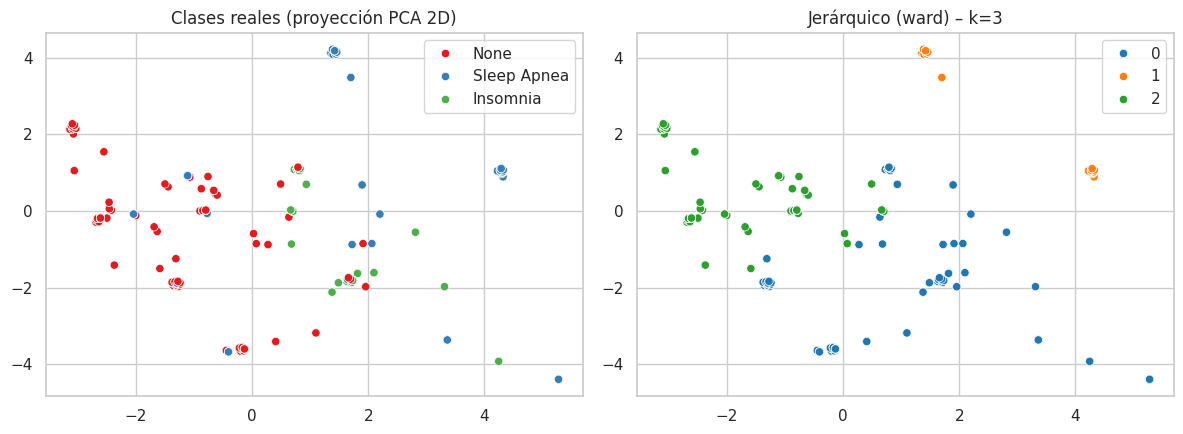

In [ ]:
# Reconstruir las etiquetas del mejor modelo y compararlas con las clases reales
def etiquetas(modelo, config):
    if modelo == "K-means":
        return KMeans(n_clusters=int(config.split("=")[1]), n_init=20, random_state=SEED).fit_predict(Xc)
    if modelo.startswith("Jerárquico"):
        return AgglomerativeClustering(n_clusters=int(config.split("=")[1]),
                                       linkage=modelo.split("(")[1][:-1]).fit_predict(Xc)
    eps = float(config.split(",")[0].split("=")[1]); ms = int(config.split("ms=")[1])
    return DBSCAN(eps=eps, min_samples=ms).fit_predict(Xc)

lab_best = etiquetas(mejor["Modelo"], mejor["Config"])
print("Clusters (filas) vs. clases reales (columnas):")
print(pd.crosstab(pd.Series(lab_best, name="Cluster"), pd.Series(le.inverse_transform(y), name="Clase real")))

p2 = PCA(2, random_state=SEED).fit_transform(Xc)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=p2[:, 0], y=p2[:, 1], hue=le.inverse_transform(y), ax=ax[0], palette="Set1")
ax[0].set_title("Clases reales (proyección PCA 2D)")
sns.scatterplot(x=p2[:, 0], y=p2[:, 1], hue=lab_best, ax=ax[1], palette="tab10")
ax[1].set_title(f"{mejor['Modelo']} – {mejor['Config']}")
plt.tight_layout(); plt.show()

### Conclusión de la Parte 1

La celda anterior identifica la variante con mayor ARI entre las configuraciones evaluadas que tienen el número de clusters más cercano a las clases originales. Para la sustentación, interpreta también NMI, pureza, Silhouette y el porcentaje de ruido de DBSCAN. No asumas que un valor alto de pureza por sí solo implica buen agrupamiento: la pureza tiende a subir cuando se crean más clusters.

# PARTE 2 – Reducción de dimensión y clasificación supervisada

## Diseño experimental

- Se reserva aproximadamente el 20 % de las muestras para prueba mediante una partición estratificada por grupos.
- Los perfiles con las mismas características de entrada se mantienen juntos para evitar que un registro duplicado aparezca simultáneamente en entrenamiento y prueba.
- Escalado, selección de características, PCA y LDA se ajustan dentro de las particiones de entrenamiento.
- Las configuraciones se eligen por validación cruzada en el conjunto de entrenamiento. El conjunto de prueba se usa para la comparación final.
- El clasificador final de esta parte es una red neuronal artificial `MLPClassifier`.
- Se reportan exactitud y F1 macro, porque el tamaño de las clases puede ser diferente.

> **Nota:** los resultados del dataset Sleep Health deben interpretarse como un ejercicio académico de clasificación, no como una herramienta de diagnóstico médico.

Muestras totales: 374
Entrenamiento: (303, 22)  | Prueba: (71, 22)
Número de perfiles distintos en train: 86
Número de perfiles distintos en test: 23
¿Hay perfiles compartidos entre train y test?: False
Clases train: {'Insomnia': np.int64(66), 'None': np.int64(169), 'Sleep Apnea': np.int64(68)}
Clases test: {'Insomnia': np.int64(11), 'None': np.int64(50), 'Sleep Apnea': np.int64(10)}
Línea base:


,Método,Dim,CV acc,CV F1-macro,CV F1-macro std,Test acc,Test F1-macro
0,Todas las características,22,0.911,0.884,0.049,0.789,0.676


              precision    recall  f1-score   support

    Insomnia       0.50      1.00      0.67        11
        None       0.98      0.82      0.89        50
 Sleep Apnea       0.57      0.40      0.47        10

    accuracy                           0.79        71
   macro avg       0.68      0.74      0.68        71
weighted avg       0.85      0.79      0.80        71



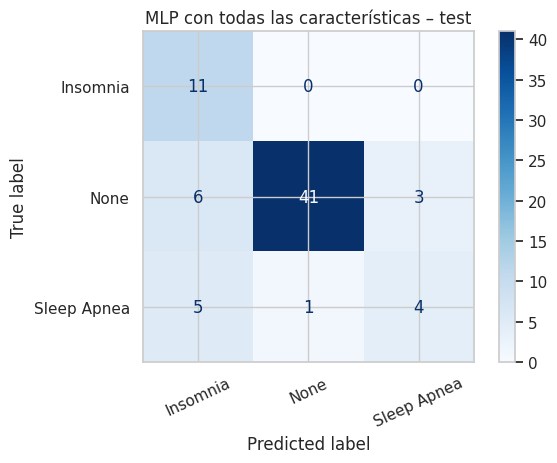

In [ ]:
# Se agrupan filas que tengan exactamente el mismo perfil de entrada X.
# Así, los perfiles repetidos se asignan siempre al mismo fold.
profile_hash = pd.util.hash_pandas_object(X, index=False)
groups = pd.factorize(profile_hash, sort=False)[0]

splitter_holdout = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter_holdout.split(X, y, groups))
X_tr, X_te = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_tr, y_te = y[train_idx], y[test_idx]
groups_tr, groups_te = groups[train_idx], groups[test_idx]

print("Muestras totales:", len(X))
print("Entrenamiento:", X_tr.shape, " | Prueba:", X_te.shape)
print("Número de perfiles distintos en train:", len(np.unique(groups_tr)))
print("Número de perfiles distintos en test:", len(np.unique(groups_te)))
print("¿Hay perfiles compartidos entre train y test?:", bool(set(groups_tr) & set(groups_te)))
print("Clases train:", dict(zip(clases, np.bincount(y_tr, minlength=n_clases))))
print("Clases test:", dict(zip(clases, np.bincount(y_te, minlength=n_clases))))

# Validación cruzada agrupada para que los perfiles idénticos no se repartan entre folds.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)


def nuevo_mlp():
    """Clasificador base de red neuronal; ajustar hiperparámetros solo con el train."""
    return MLPClassifier(
        hidden_layer_sizes=(32, 16), activation="relu", alpha=1e-3,
        max_iter=2500, random_state=SEED, early_stopping=False
    )

SCORING = {"accuracy": "accuracy", "f1_macro": "f1_macro"}

# Línea base: todas las características.
base = make_pipeline(StandardScaler(), nuevo_mlp())
cv_base = cross_validate(
    base, X_tr, y_tr, groups=groups_tr, cv=cv,
    scoring=SCORING, n_jobs=-1, return_train_score=False
)
base.fit(X_tr, y_tr)
pred_base = base.predict(X_te)
res_base = {
    "Método": "Todas las características", "Dim": X.shape[1],
    "CV acc": cv_base["test_accuracy"].mean(),
    "CV F1-macro": cv_base["test_f1_macro"].mean(),
    "CV F1-macro std": cv_base["test_f1_macro"].std(),
    "Test acc": accuracy_score(y_te, pred_base),
    "Test F1-macro": f1_score(y_te, pred_base, average="macro", zero_division=0)
}
print("Línea base:")
display(pd.DataFrame([res_base]).round(3))
print(classification_report(y_te, pred_base, labels=np.arange(n_clases), target_names=clases, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_te, pred_base, labels=np.arange(n_clases), display_labels=clases, cmap="Blues", xticks_rotation=25)
plt.title("MLP con todas las características – test")
plt.tight_layout()
plt.show()

## 1. Selección de características: wrapper + SFFS

SFFS (*Sequential Floating Forward Selection*) añade iterativamente la característica que mejora más el criterio y puede retirar características ya seleccionadas cuando eso mejora la puntuación. El *wrapper* es el estimador utilizado para evaluar subconjuntos durante la búsqueda.

Se comparan KNN, árbol de decisión y regresión logística como wrappers. Para mantener el tiempo de cálculo razonable, la búsqueda se limita a un máximo de 15 características (o menos si el dataset tiene menos); puedes aumentar este límite en la celda siguiente si tu equipo lo permite. Para evitar que el resultado de validación sea demasiado optimista, la comparación se realiza con **validación cruzada externa**: en cada fold externo, SFFS se ajusta únicamente sobre el fold de entrenamiento y una MLP evalúa el subconjunto en el fold externo de validación. Los folds internos también respetan los grupos de perfiles repetidos.

In [ ]:
MAX_FEATURES_SFFS = min(15, X.shape[1])
print(f"SFFS evaluará subconjuntos de 1 a {MAX_FEATURES_SFFS} características; total de características disponibles: {X.shape[1]}.")

wrappers = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Regresión logística": LogisticRegression(max_iter=2000, random_state=SEED)
}

outer_cv_sffs = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 2)
outer_splits = list(outer_cv_sffs.split(X_tr, y_tr, groups_tr))
sffs_nested_rows = []

for nombre, wrapper in wrappers.items():
    acc_outer, f1_outer = [], []
    print(f"Evaluación anidada SFFS con wrapper: {nombre}")

    for fold, (idx_fit, idx_val) in enumerate(outer_splits, start=1):
        X_fit, X_val = X_tr.iloc[idx_fit], X_tr.iloc[idx_val]
        y_fit, y_val = y_tr[idx_fit], y_tr[idx_val]
        groups_fit = groups_tr[idx_fit]

        inner_cv = list(
            StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + fold)
            .split(X_fit, y_fit, groups_fit)
        )
        selector = SFS(
            estimator=make_pipeline(StandardScaler(), clone(wrapper)),
            k_features=(1, MAX_FEATURES_SFFS), forward=True, floating=True,
            scoring="f1_macro", cv=inner_cv, n_jobs=-1
        )
        selector.fit(X_fit, y_fit)
        selected = list(selector.k_feature_names_)

        mlp = make_pipeline(StandardScaler(), nuevo_mlp())
        mlp.fit(X_fit[selected], y_fit)
        pred_val = mlp.predict(X_val[selected])
        acc_outer.append(accuracy_score(y_val, pred_val))
        f1_outer.append(f1_score(y_val, pred_val, average="macro", zero_division=0))
        print(f"  Fold {fold}: {len(selected)} características; accuracy={acc_outer[-1]:.3f}; F1 macro={f1_outer[-1]:.3f}")

    sffs_nested_rows.append({
        "Wrapper": nombre,
        "MLP CV acc": float(np.mean(acc_outer)),
        "MLP CV acc std": float(np.std(acc_outer)),
        "MLP CV F1-macro": float(np.mean(f1_outer)),
        "MLP CV F1-macro std": float(np.std(f1_outer))
    })

sffs_cv_df = pd.DataFrame(sffs_nested_rows).sort_values(
    ["MLP CV F1-macro", "MLP CV acc"], ascending=False
).reset_index(drop=True)
display(sffs_cv_df.round(3))

# La opción de wrapper se selecciona con F1 macro en CV externa, no con el test.
mejor_wrapper = sffs_cv_df.iloc[0]["Wrapper"]
print("Wrapper seleccionado por validación cruzada externa:", mejor_wrapper)

SFFS evaluará subconjuntos de 1 a 15 características; total de características disponibles: 22.
Evaluación anidada SFFS con wrapper: KNN (k=5)
  Fold 1: 11 características; accuracy=0.948; F1 macro=0.945
  Fold 2: 4 características; accuracy=0.908; F1 macro=0.880
  Fold 3: 5 características; accuracy=0.923; F1 macro=0.912
  Fold 4: 4 características; accuracy=0.683; F1 macro=0.692
  Fold 5: 6 características; accuracy=0.947; F1 macro=0.903
Evaluación anidada SFFS con wrapper: Árbol de decisión
  Fold 1: 9 características; accuracy=0.948; F1 macro=0.945
  Fold 2: 4 características; accuracy=0.908; F1 macro=0.880
  Fold 3: 3 características; accuracy=0.923; F1 macro=0.912
  Fold 4: 5 características; accuracy=0.833; F1 macro=0.789
  Fold 5: 3 características; accuracy=0.965; F1 macro=0.932
Evaluación anidada SFFS con wrapper: Regresión logística
  Fold 1: 4 características; accuracy=0.948; F1 macro=0.945
  Fold 2: 8 características; accuracy=0.908; F1 macro=0.880
  Fold 3: 7 característi

,Wrapper,MLP CV acc,MLP CV acc std,MLP CV F1-macro,MLP CV F1-macro std
0,Árbol de decisión,0.915,0.046,0.892,0.056
1,Regresión logística,0.908,0.051,0.883,0.066
2,KNN (k=5),0.882,0.100,0.866,0.090


Wrapper seleccionado por validación cruzada externa: Árbol de decisión


KNN (k=5): 6 características seleccionadas -> ['Sleep Duration', 'Systolic', 'Diastolic', 'Occ_Lawyer', 'Occ_Salesperson', 'Occ_Software Engineer']
Árbol de decisión: 7 características seleccionadas -> ['Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Daily Steps', 'Diastolic', 'Occ_Engineer', 'Occ_Sales Representative']
Regresión logística: 6 características seleccionadas -> ['Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Systolic', 'Occ_Doctor', 'Occ_Nurse']
Subconjunto final de características: ['Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Daily Steps', 'Diastolic', 'Occ_Engineer', 'Occ_Sales Representative']


,Método,Dim,CV acc,CV F1-macro,CV F1-macro std,Test acc,Test F1-macro
0,SFFS (Árbol de decisión),7,0.915,0.892,0.056,0.817,0.722


              precision    recall  f1-score   support

    Insomnia       0.50      0.82      0.62        11
        None       0.98      0.86      0.91        50
 Sleep Apnea       0.67      0.60      0.63        10

    accuracy                           0.82        71
   macro avg       0.71      0.76      0.72        71
weighted avg       0.86      0.82      0.83        71



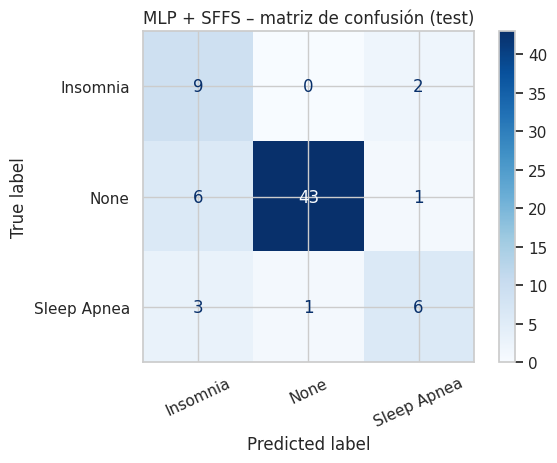

In [ ]:
# Ajuste final de SFFS en todo el conjunto de entrenamiento.
# Estos resultados internos sirven para seleccionar características; la estimación
# menos sesgada del flujo SFFS+MLP es la validación cruzada externa de la celda anterior.
inner_splits_full = list(
    StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 3)
    .split(X_tr, y_tr, groups_tr)
)
sffs_sel = {}

for nombre, wrapper in wrappers.items():
    sfs = SFS(
        estimator=make_pipeline(StandardScaler(), clone(wrapper)),
        k_features=(1, MAX_FEATURES_SFFS), forward=True, floating=True,
        scoring="f1_macro", cv=inner_splits_full, n_jobs=-1
    )
    sfs.fit(X_tr, y_tr)
    feats = list(sfs.k_feature_names_)
    sffs_sel[nombre] = (feats, sfs)
    print(f"{nombre}: {len(feats)} características seleccionadas -> {feats}")

feats_best = sffs_sel[mejor_wrapper][0]
final_sffs = make_pipeline(StandardScaler(), nuevo_mlp())
final_sffs.fit(X_tr[feats_best], y_tr)
pred_sffs = final_sffs.predict(X_te[feats_best])

fila_cv_sffs = sffs_cv_df.loc[sffs_cv_df["Wrapper"] == mejor_wrapper].iloc[0]
res_sffs = {
    "Método": f"SFFS ({mejor_wrapper})", "Dim": len(feats_best),
    "CV acc": fila_cv_sffs["MLP CV acc"],
    "CV F1-macro": fila_cv_sffs["MLP CV F1-macro"],
    "CV F1-macro std": fila_cv_sffs["MLP CV F1-macro std"],
    "Test acc": accuracy_score(y_te, pred_sffs),
    "Test F1-macro": f1_score(y_te, pred_sffs, average="macro", zero_division=0)
}
print("Subconjunto final de características:", feats_best)
display(pd.DataFrame([res_sffs]).round(3))
print(classification_report(y_te, pred_sffs, labels=np.arange(n_clases), target_names=clases, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_te, pred_sffs, labels=np.arange(n_clases), display_labels=clases, cmap="Blues", xticks_rotation=25)
plt.title("MLP + SFFS – matriz de confusión (test)")
plt.tight_layout()
plt.show()

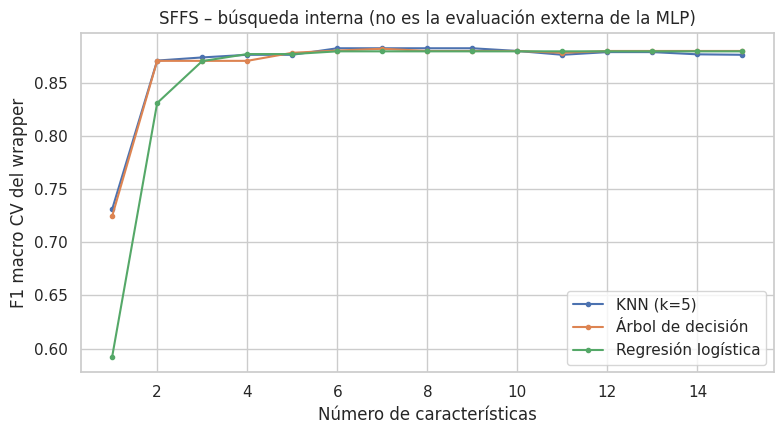

In [ ]:
# Curvas de la puntuación interna del wrapper frente al número de características.
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, (feats, sfs) in sffs_sel.items():
    metricas = sfs.get_metric_dict()
    ks = sorted(metricas.keys(), key=lambda k: len(metricas[k]["feature_idx"]))
    dimensiones = [len(metricas[k]["feature_idx"]) for k in ks]
    puntuaciones = [metricas[k]["avg_score"] for k in ks]
    ax.plot(dimensiones, puntuaciones, "o-", ms=3, label=nombre)
ax.set_xlabel("Número de características")
ax.set_ylabel("F1 macro CV del wrapper")
ax.set_title("SFFS – búsqueda interna (no es la evaluación externa de la MLP)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Variables más importantes (discriminantes)

Se combinan dos evidencias complementarias: (a) qué características selecciona SFFS y con qué frecuencia aparecen entre los tres wrappers, y (b) la importancia por permutación de la MLP base evaluada en el conjunto de prueba. La importancia por permutación es una medida predictiva, no prueba causalidad.

/tmp/ipykernel_570/1379026418.py:16: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  importancia = importancia.fillna({"Veces seleccionada (de 3 wrappers)": 0, "En el mejor wrapper": False})


,Veces seleccionada (de 3 wrappers),En el mejor wrapper,Caída F1-macro por permutación
Occ_Lawyer,1.0,False,0.1308
BMI_ord,0.0,False,0.1164
Occ_Nurse,1.0,False,0.1084
Systolic,2.0,False,0.0472
Heart Rate,0.0,False,0.0377
Diastolic,2.0,True,0.0334
Quality of Sleep,2.0,True,0.0292
Daily Steps,1.0,True,0.0141
Age,0.0,False,0.0120
Occ_Teacher,0.0,False,0.0098


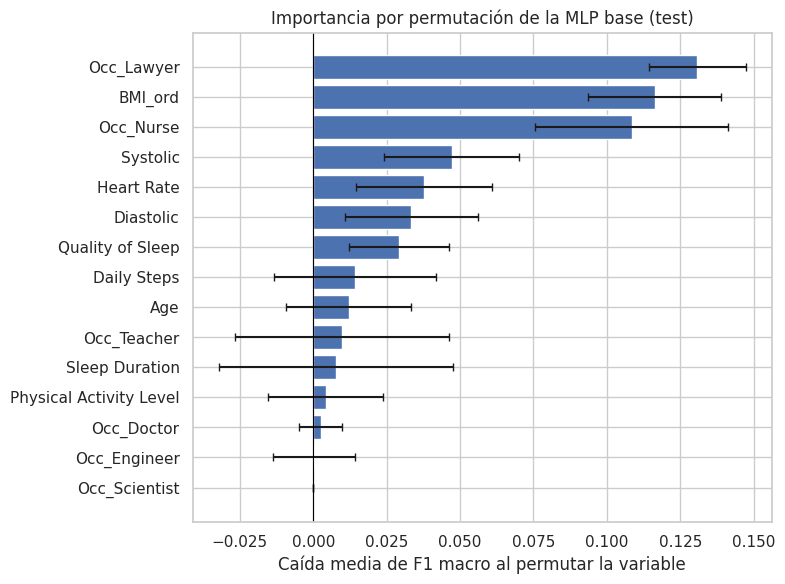

In [ ]:
# (a) Frecuencia de selección en los tres wrappers finales.
freq_series = pd.Series([f for feats, _ in sffs_sel.values() for f in feats]).value_counts()
freq = freq_series.rename("Veces seleccionada (de 3 wrappers)").to_frame()
freq["En el mejor wrapper"] = freq.index.isin(feats_best)

# (b) Importancia por permutación de la MLP base (todas las características),
# calculada sobre el test con F1 macro como criterio.
pi = permutation_importance(
    base, X_te, y_te, n_repeats=20, random_state=SEED,
    scoring="f1_macro", n_jobs=-1
)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
imp_std = pd.Series(pi.importances_std, index=X.columns)

importancia = freq.join(imp.rename("Caída F1-macro por permutación"), how="outer")
importancia = importancia.fillna({"Veces seleccionada (de 3 wrappers)": 0, "En el mejor wrapper": False})
importancia = importancia.sort_values("Caída F1-macro por permutación", ascending=False)
display(importancia.round(4))

imp_top = imp.head(15).sort_values()
plt.figure(figsize=(8, 6))
plt.barh(imp_top.index, imp_top.values, xerr=imp_std[imp_top.index], capsize=3)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Caída media de F1 macro al permutar la variable")
plt.title("Importancia por permutación de la MLP base (test)")
plt.tight_layout()
plt.show()

In [ ]:
# Resumen descriptivo para ayudar a interpretar las variables seleccionadas.
feature_descriptions = {
    "Age": "edad en años",
    "Sleep Duration": "duración del sueño en horas",
    "Quality of Sleep": "calidad de sueño auto-reportada (escala ordinal)",
    "Physical Activity Level": "nivel/tiempo de actividad física reportado",
    "Stress Level": "nivel de estrés auto-reportado (escala ordinal)",
    "Heart Rate": "frecuencia cardíaca reportada",
    "Daily Steps": "pasos diarios",
    "Systolic": "presión sistólica",
    "Diastolic": "presión diastólica",
    "BMI_ord": "categoría ordinal de IMC",
    "Gender_Male": "indicador de género masculino"
}
for col in X.columns:
    if col.startswith("Occ_"):
        feature_descriptions[col] = "indicador de ocupación: " + col.replace("Occ_", "")

print("Características seleccionadas por el mejor wrapper:")
for f in feats_best:
    print(f"- {f}: {feature_descriptions.get(f, f)}")

print("\nMedianas por clase para las variables numéricas seleccionadas:")
num_selected = [f for f in feats_best if f in num_feats]
if num_selected:
    tabla_medianas = d.assign(Clase=le.inverse_transform(y)).groupby("Clase")[num_selected].median().T
    display(tabla_medianas)
else:
    print("El subconjunto no contiene variables numéricas continuas/discretas de la lista original.")

print("\nGuía de interpretación:")
print("1. Variables seleccionadas por varios wrappers son candidatas consistentes.")
print("2. Una caída positiva de F1 macro al permutar una variable indica que el modelo dependía de ella en este test.")
print("3. Una importancia cercana a cero o negativa no demuestra por sí sola que una variable sea inútil; puede haber variables correlacionadas o variación muestral.")

Características seleccionadas por el mejor wrapper:
- Sleep Duration: duración del sueño en horas
- Quality of Sleep: calidad de sueño auto-reportada (escala ordinal)
- Physical Activity Level: nivel/tiempo de actividad física reportado
- Daily Steps: pasos diarios
- Diastolic: presión diastólica
- Occ_Engineer: indicador de ocupación: Engineer
- Occ_Sales Representative: indicador de ocupación: Sales Representative

Medianas por clase para las variables numéricas seleccionadas:


Clase,Insomnia,None,Sleep Apnea
Sleep Duration,6.5,7.4,6.8
Quality of Sleep,7.0,8.0,6.0
Physical Activity Level,45.0,60.0,75.0
Daily Steps,6000.0,7000.0,7000.0
Diastolic,85.0,80.0,95.0



Guía de interpretación:
1. Variables seleccionadas por varios wrappers son candidatas consistentes.
2. Una caída positiva de F1 macro al permutar una variable indica que el modelo dependía de ella en este test.
3. Una importancia cercana a cero o negativa no demuestra por sí sola que una variable sea inútil; puede haber variables correlacionadas o variación muestral.


## 3. Reducción de dimensión con PCA

PCA es un método no supervisado que proyecta los datos sobre direcciones de máxima varianza. Se evalúan de 1 a `p` componentes con una MLP. En cada fold, tanto el escalado como PCA se ajustan exclusivamente con los datos de entrenamiento de ese fold. La dimensión se elige por F1 macro de validación cruzada y no usando el conjunto de prueba.

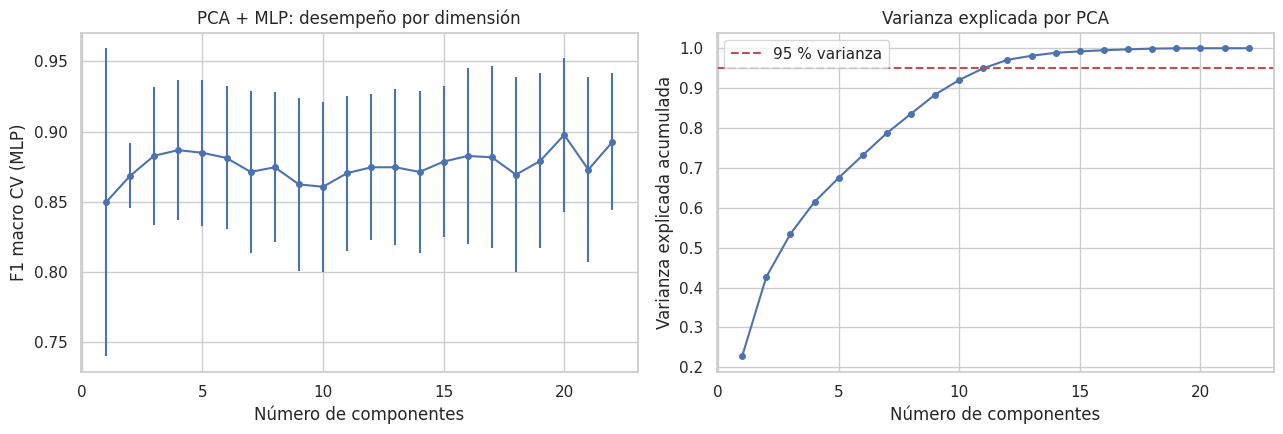

Mejor dimensión PCA por CV F1-macro: 20
Varianza acumulada para 20 componente(s): 100.00%


,Método,Dim,CV acc,CV F1-macro,CV F1-macro std,Test acc,Test F1-macro
0,PCA,20,0.919,0.898,0.055,0.789,0.655


              precision    recall  f1-score   support

    Insomnia       0.45      0.82      0.58        11
        None       0.98      0.86      0.91        50
 Sleep Apnea       0.57      0.40      0.47        10

    accuracy                           0.79        71
   macro avg       0.67      0.69      0.66        71
weighted avg       0.84      0.79      0.80        71



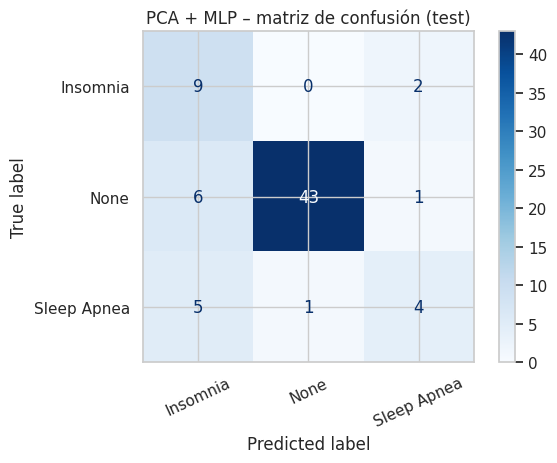

,Componentes,CV acc,CV acc std,CV F1-macro,CV F1-macro std
0,1,0.890,0.069,0.850,0.110
1,2,0.903,0.020,0.868,0.023
2,3,0.911,0.035,0.883,0.049
3,4,0.915,0.035,0.887,0.050
4,5,0.911,0.036,0.885,0.052
5,6,0.911,0.037,0.881,0.051
6,7,0.901,0.043,0.871,0.058
7,8,0.905,0.040,0.875,0.053
8,9,0.894,0.049,0.862,0.062
9,10,0.892,0.046,0.861,0.061


In [ ]:
p_total = X.shape[1]
pca_rows = []
for dcomp in range(1, p_total + 1):
    pipe = make_pipeline(StandardScaler(), PCA(n_components=dcomp, random_state=SEED), nuevo_mlp())
    scores = cross_validate(
        pipe, X_tr, y_tr, groups=groups_tr, cv=cv,
        scoring=SCORING, n_jobs=-1, return_train_score=False
    )
    pca_rows.append({
        "Componentes": dcomp,
        "CV acc": scores["test_accuracy"].mean(),
        "CV acc std": scores["test_accuracy"].std(),
        "CV F1-macro": scores["test_f1_macro"].mean(),
        "CV F1-macro std": scores["test_f1_macro"].std()
    })
pca_df = pd.DataFrame(pca_rows)

pca_full = make_pipeline(StandardScaler(), PCA()).fit(X_tr)
var_cum = np.cumsum(pca_full[-1].explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].errorbar(pca_df["Componentes"], pca_df["CV F1-macro"], yerr=pca_df["CV F1-macro std"], fmt="o-", ms=4)
ax[0].set_xlabel("Número de componentes")
ax[0].set_ylabel("F1 macro CV (MLP)")
ax[0].set_title("PCA + MLP: desempeño por dimensión")
ax[1].plot(range(1, p_total + 1), var_cum, "o-", ms=4)
ax[1].axhline(0.95, color="r", ls="--", label="95 % varianza")
ax[1].set_xlabel("Número de componentes")
ax[1].set_ylabel("Varianza explicada acumulada")
ax[1].set_title("Varianza explicada por PCA")
ax[1].legend()
plt.tight_layout()
plt.show()

d_pca = int(pca_df.loc[pca_df["CV F1-macro"].idxmax(), "Componentes"])
pipe_pca = make_pipeline(StandardScaler(), PCA(n_components=d_pca, random_state=SEED), nuevo_mlp())
pipe_pca.fit(X_tr, y_tr)
pred_pca = pipe_pca.predict(X_te)
res_pca = {
    "Método": "PCA", "Dim": d_pca,
    "CV acc": pca_df.loc[pca_df["Componentes"] == d_pca, "CV acc"].iloc[0],
    "CV F1-macro": pca_df.loc[pca_df["Componentes"] == d_pca, "CV F1-macro"].iloc[0],
    "CV F1-macro std": pca_df.loc[pca_df["Componentes"] == d_pca, "CV F1-macro std"].iloc[0],
    "Test acc": accuracy_score(y_te, pred_pca),
    "Test F1-macro": f1_score(y_te, pred_pca, average="macro", zero_division=0)
}
print(f"Mejor dimensión PCA por CV F1-macro: {d_pca}")
print(f"Varianza acumulada para {d_pca} componente(s): {var_cum[d_pca - 1]:.2%}")
display(pd.DataFrame([res_pca]).round(3))
print(classification_report(y_te, pred_pca, labels=np.arange(n_clases), target_names=clases, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_te, pred_pca, labels=np.arange(n_clases), display_labels=clases, cmap="Blues", xticks_rotation=25)
plt.title("PCA + MLP – matriz de confusión (test)")
plt.tight_layout()
plt.show()
display(pca_df.round(3))

## 4. Reducción de dimensión con LDA

LDA es supervisado: usa las etiquetas del entrenamiento para encontrar direcciones que separen las clases. Su número máximo de componentes es `min(n_clases - 1, n_características)`. Para tres clases se pueden evaluar como máximo dos componentes. En cada fold, LDA se ajusta solo con las etiquetas de entrenamiento de ese fold.

Mejor dimensión LDA por CV F1-macro: 2


,Método,Dim,CV acc,CV F1-macro,CV F1-macro std,Test acc,Test F1-macro
0,LDA,2,0.915,0.888,0.061,0.775,0.631


              precision    recall  f1-score   support

    Insomnia       0.42      0.73      0.53        11
        None       0.98      0.86      0.91        50
 Sleep Apnea       0.50      0.40      0.44        10

    accuracy                           0.77        71
   macro avg       0.63      0.66      0.63        71
weighted avg       0.82      0.77      0.79        71



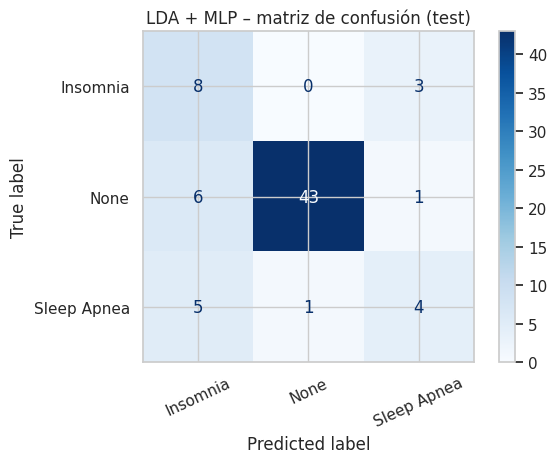

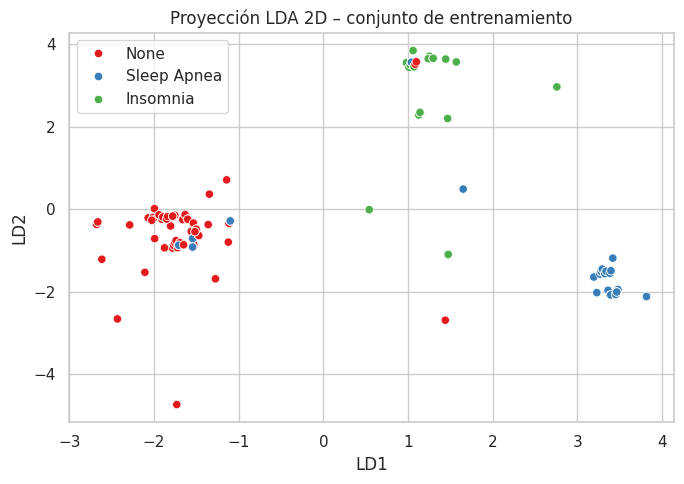

,Componentes,CV acc,CV acc std,CV F1-macro,CV F1-macro std
0,1,0.864,0.091,0.845,0.097
1,2,0.915,0.044,0.888,0.061


In [ ]:
max_lda = min(n_clases - 1, p_total)
lda_rows = []
for dcomp in range(1, max_lda + 1):
    pipe = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=dcomp), nuevo_mlp())
    scores = cross_validate(
        pipe, X_tr, y_tr, groups=groups_tr, cv=cv,
        scoring=SCORING, n_jobs=-1, return_train_score=False
    )
    lda_rows.append({
        "Componentes": dcomp,
        "CV acc": scores["test_accuracy"].mean(),
        "CV acc std": scores["test_accuracy"].std(),
        "CV F1-macro": scores["test_f1_macro"].mean(),
        "CV F1-macro std": scores["test_f1_macro"].std()
    })
lda_df = pd.DataFrame(lda_rows)

d_lda = int(lda_df.loc[lda_df["CV F1-macro"].idxmax(), "Componentes"])
pipe_lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=d_lda), nuevo_mlp())
pipe_lda.fit(X_tr, y_tr)
pred_lda = pipe_lda.predict(X_te)
res_lda = {
    "Método": "LDA", "Dim": d_lda,
    "CV acc": lda_df.loc[lda_df["Componentes"] == d_lda, "CV acc"].iloc[0],
    "CV F1-macro": lda_df.loc[lda_df["Componentes"] == d_lda, "CV F1-macro"].iloc[0],
    "CV F1-macro std": lda_df.loc[lda_df["Componentes"] == d_lda, "CV F1-macro std"].iloc[0],
    "Test acc": accuracy_score(y_te, pred_lda),
    "Test F1-macro": f1_score(y_te, pred_lda, average="macro", zero_division=0)
}
print(f"Mejor dimensión LDA por CV F1-macro: {d_lda}")
display(pd.DataFrame([res_lda]).round(3))
print(classification_report(y_te, pred_lda, labels=np.arange(n_clases), target_names=clases, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_te, pred_lda, labels=np.arange(n_clases), display_labels=clases, cmap="Blues", xticks_rotation=25)
plt.title("LDA + MLP – matriz de confusión (test)")
plt.tight_layout()
plt.show()

# Proyección LDA 2D solo si el problema permite dos componentes.
if max_lda >= 2:
    lda2 = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2)).fit(X_tr, y_tr)
    Z2 = lda2.transform(X_tr)
    plt.figure(figsize=(7, 5))
    sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=le.inverse_transform(y_tr), palette="Set1")
    plt.xlabel("LD1")
    plt.ylabel("LD2")
    plt.title("Proyección LDA 2D – conjunto de entrenamiento")
    plt.tight_layout()
    plt.show()

display(lda_df.round(3))

## 5. Comparación final y conclusiones

La selección de la mejor técnica se realiza usando F1 macro de validación cruzada; los resultados del conjunto de prueba se reportan para comparar el desempeño final. La tabla no debe interpretarse como prueba de que una técnica será siempre superior: el dataset es pequeño y la composición de los folds puede influir en las métricas.

,Método,Dim,CV acc,CV F1-macro,CV F1-macro std,Test acc,Test F1-macro
0,Todas las características,22,0.911,0.884,0.049,0.789,0.676
1,SFFS (Árbol de decisión),7,0.915,0.892,0.056,0.817,0.722
2,PCA,20,0.919,0.898,0.055,0.789,0.655
3,LDA,2,0.915,0.888,0.061,0.775,0.631


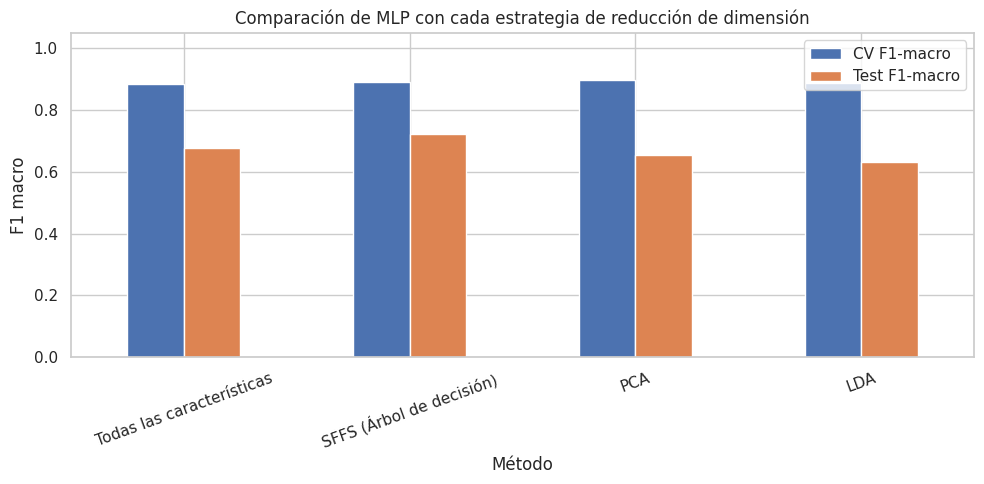

Mejor resultado según CV F1-macro: PCA con dimensión 20.
F1 macro CV=0.898; F1 macro test=0.655; accuracy test=0.789


In [ ]:
final = pd.DataFrame([res_base, res_sffs, res_pca, res_lda])
display(final.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
final.set_index("Método")[["CV F1-macro", "Test F1-macro"]].plot.bar(ax=ax, rot=20)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 macro")
ax.set_title("Comparación de MLP con cada estrategia de reducción de dimensión")
plt.tight_layout()
plt.show()

mejor_final = final.sort_values(["CV F1-macro", "Dim"], ascending=[False, True]).iloc[0]
print(f"Mejor resultado según CV F1-macro: {mejor_final['Método']} con dimensión {int(mejor_final['Dim'])}.")
print(f"F1 macro CV={mejor_final['CV F1-macro']:.3f}; F1 macro test={mejor_final['Test F1-macro']:.3f}; accuracy test={mejor_final['Test acc']:.3f}")

### Conclusiones generadas a partir de los resultados

Ejecuta el notebook completo y usa la salida de la celda siguiente para redactar la conclusión definitiva. No copies cifras de ejemplos externos ni inventes resultados.

In [ ]:
# Resumen automático para apoyar la redacción de conclusiones.
print("PARTE 1 – CLUSTERING")
print(f"Variante con mayor ARI entre las configuraciones comparadas: {mejor['Modelo']} ({mejor['Config']}).")
print(f"ARI={mejor['ARI']:.3f}; NMI={mejor['NMI']:.3f}; pureza={mejor['Pureza']:.3f}; Silhouette={mejor['Silhouette']:.3f}.")
if mejor['Modelo'] == 'DBSCAN':
    print(f"DBSCAN etiquetó {int(mejor['Ruido'])} muestras como ruido en la configuración seleccionada.")
else:
    print("La configuración seleccionada no utiliza una etiqueta explícita de ruido.")

print("\nPARTE 2 – REDUCCIÓN DE DIMENSIÓN")
print(f"SFFS seleccionó {len(feats_best)} característica(s) con el wrapper {mejor_wrapper}: {feats_best}.")
print(f"PCA: mejor dimensión={d_pca}, varianza acumulada de entrenamiento={var_cum[d_pca-1]:.2%}.")
print(f"LDA: mejor dimensión={d_lda}.")
print(f"Mejor estrategia por F1 macro CV={mejor_final['Método']} (F1 macro CV={mejor_final['CV F1-macro']:.3f}).")
print("\nAntes de entregar: interpreta estos resultados, menciona las limitaciones del dataset y sube el notebook junto con instrucciones y fuente de datos al repositorio de GitHub.")

PARTE 1 – CLUSTERING
Variante con mayor ARI entre las configuraciones comparadas: Jerárquico (ward) (k=3).
ARI=0.314; NMI=0.359; pureza=0.730; Silhouette=0.269.
La configuración seleccionada no utiliza una etiqueta explícita de ruido.

PARTE 2 – REDUCCIÓN DE DIMENSIÓN
SFFS seleccionó 7 característica(s) con el wrapper Árbol de decisión: ['Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Daily Steps', 'Diastolic', 'Occ_Engineer', 'Occ_Sales Representative'].
PCA: mejor dimensión=20, varianza acumulada de entrenamiento=100.00%.
LDA: mejor dimensión=2.
Mejor estrategia por F1 macro CV=PCA (F1 macro CV=0.898).

Antes de entregar: interpreta estos resultados, menciona las limitaciones del dataset y sube el notebook junto con instrucciones y fuente de datos al repositorio de GitHub.
